Clocked VAE - UCI Absenteeism at Work Pretraining Experiment

This notebook tests whether the public UCI Absenteeism at Work dataset can improve the Clocked VAE.

This experiment compares:

1. Clocked-only VAE
2. UCI-pretrained VAE -> fine-tuned on Clocked


In [1]:
# libraries

import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch:", torch.__version__)


PyTorch: 2.14.1


1. Load Clocked data

In [ ]:
clocked_path = Path("unified_attendance_1250.csv")

clocked = pd.read_csv(clocked_path)

clocked = clocked[
    clocked["fraud_label"].notna()
].copy()

clocked["fraud_label"] = (
    clocked["fraud_label"]
    .astype(int)
)

clocked["clock_in_at"] = pd.to_datetime(
    clocked["clock_in_at"],
    errors="coerce",
)

clocked = clocked.dropna(
    subset=[
        "clock_in_at",
        "shift_hours",
        "employee_id",
    ]
).copy()

print("Clocked labelled rows:", len(clocked))
print(clocked["fraud_label"].value_counts())


Clocked labelled rows: 1000
fraud_label
0    820
1    180
Name: count, dtype: int64


2. Create the Clocked train/test split first

The test set is kept untouched.

Normal behaviour references are calculated only from normal records in the Clocked training split.


In [3]:
train_df, test_df = train_test_split(
    clocked,
    test_size=0.30,
    random_state=SEED,
    stratify=clocked["fraud_label"],
)

normal_train = train_df[
    train_df["fraud_label"] == 0
].copy()

print("Normal Clocked training rows:", len(normal_train))
print("Clocked test rows:", len(test_df))
print("Clocked test fraud rows:", int(test_df["fraud_label"].sum()))


Normal Clocked training rows: 574
Clocked test rows: 300
Clocked test fraud rows: 54


3. Shared workplace-behaviour representation


In [4]:
FEATURES = [
    "day_sin",
    "day_cos",
    "month_sin",
    "month_cos",
    "work_disruption",
    "large_disruption",
]


def cyclical_features(day_index, month):
    day_index = np.asarray(day_index, dtype=float)
    month = np.asarray(month, dtype=float)

    day_angle = 2 * np.pi * day_index / 7.0
    month_angle = 2 * np.pi * (month - 1.0) / 12.0

    return (
        np.sin(day_angle),
        np.cos(day_angle),
        np.sin(month_angle),
        np.cos(month_angle),
    )


employee_shift_reference = (
    normal_train
    .groupby("employee_id")["shift_hours"]
    .median()
    .to_dict()
)

global_shift_reference = float(
    normal_train["shift_hours"].median()
)


def make_clocked_features(data):
    rows = []

    for _, row in data.iterrows():
        normal_shift = float(
            employee_shift_reference.get(
                row["employee_id"],
                global_shift_reference,
            )
        )

        normal_shift = max(normal_shift, 1.0)

        disruption_raw = abs(
            float(row["shift_hours"]) - normal_shift
        ) / normal_shift

        disruption = np.clip(
            disruption_raw,
            0.0,
            2.0,
        ) / 2.0

        large_disruption = float(
            disruption_raw >= 0.50
        )

        day_index = row["clock_in_at"].dayofweek
        month = row["clock_in_at"].month

        day_sin, day_cos, month_sin, month_cos = cyclical_features(
            day_index,
            month,
        )

        rows.append([
            day_sin,
            day_cos,
            month_sin,
            month_cos,
            disruption,
            large_disruption,
        ])

    return np.asarray(rows, dtype=np.float32)


X_clocked_train = make_clocked_features(
    normal_train
)

X_clocked_test = make_clocked_features(
    test_df
)

y_clocked_test = (
    test_df["fraud_label"]
    .to_numpy(dtype=int)
)

print("Clocked normal training shape:", X_clocked_train.shape)
print("Clocked test shape:", X_clocked_test.shape)


Clocked normal training shape: (574, 6)
Clocked test shape: (300, 6)


4. Load UCI Absenteeism at Work

In [5]:
uci_path = Path("Absenteeism_at_work.csv")

if uci_path.exists():
    # official file is normally semicolon-delimited
    uci = pd.read_csv(
        uci_path,
        sep=None,
        engine="python",
    )

    print("Loaded local UCI CSV.")

else:
    print("Local CSV not found. Trying ucimlrepo...")

    try:
        from ucimlrepo import fetch_ucirepo

        dataset = fetch_ucirepo(id=445)

        X_uci = dataset.data.features.copy()
        y_uci = dataset.data.targets.copy()

        uci = pd.concat(
            [X_uci, y_uci],
            axis=1,
        )

        print("Downloaded UCI dataset with ucimlrepo.")

    except Exception as error:
        raise FileNotFoundError(
            "Download Absenteeism_at_work.csv from the official UCI page "
            "and put it beside this notebook. Original error: "
            + str(error)
        )

uci.columns = [
    str(column).strip()
    for column in uci.columns
]

print("UCI rows:", len(uci))
print("UCI columns:")
for column in uci.columns:
    print("-", column)

display(uci.head())


Loaded local UCI CSV.
UCI rows: 740
UCI columns:
- ID
- Reason for absence
- Month of absence
- Day of the week
- Seasons
- Transportation expense
- Distance from Residence to Work
- Service time
- Age
- Work load Average/day
- Hit target
- Disciplinary failure
- Education
- Son
- Social drinker
- Social smoker
- Pet
- Weight
- Height
- Body mass index
- Absenteeism time in hours


,ID,Reason for absence,Month of absence,Day of the week,Seasons,Transportation expense,Distance from Residence to Work,Service time,Age,Work load Average/day,...,Disciplinary failure,Education,Son,Social drinker,Social smoker,Pet,Weight,Height,Body mass index,Absenteeism time in hours
0,11,26,7,3,1,289,36,13,33,239.554,...,0,1,2,1,0,1,90,172,30,4
1,36,0,7,3,1,118,13,18,50,239.554,...,1,1,1,1,0,0,98,178,31,0
2,3,23,7,4,1,179,51,18,38,239.554,...,0,1,0,1,0,0,89,170,31,2
3,7,7,7,5,1,279,5,14,39,239.554,...,0,1,2,1,1,0,68,168,24,4
4,11,23,7,5,1,289,36,13,33,239.554,...,0,1,2,1,0,1,90,172,30,2


5. Clean the UCI variables


In [6]:
def find_column(target):
    target_clean = target.lower().replace("_", " ").strip()

    for column in uci.columns:
        column_clean = (
            str(column)
            .lower()
            .replace("_", " ")
            .strip()
        )

        if column_clean == target_clean:
            return column

    raise KeyError(
        f"Could not find UCI column: {target}"
    )


reason_col = find_column("Reason for absence")
month_col = find_column("Month of absence")
day_col = find_column("Day of the week")
disciplinary_col = find_column("Disciplinary failure")
absence_hours_col = find_column("Absenteeism time in hours")

for column in [
    reason_col,
    month_col,
    day_col,
    disciplinary_col,
    absence_hours_col,
]:
    uci[column] = pd.to_numeric(
        uci[column],
        errors="coerce",
    )

uci = uci.dropna(
    subset=[
        reason_col,
        month_col,
        day_col,
        disciplinary_col,
        absence_hours_col,
    ]
).copy()

print("Clean UCI rows:", len(uci))


Clean UCI rows: 740


In [7]:
uci_routine = uci[
    (uci[disciplinary_col] == 0)
    & (uci[reason_col] != 26)
    & (uci[absence_hours_col] <= 8)
].copy()

print("UCI total rows:", len(uci))
print("UCI routine rows used for pretraining:", len(uci_routine))
print(
    "Rows excluded from pretraining:",
    len(uci) - len(uci_routine),
)


UCI total rows: 740
UCI routine rows used for pretraining: 605
Rows excluded from pretraining: 135


6. Convert UCI into the same six-feature space

In [8]:
def make_uci_features(data):
    # convert UCI Monday=2 ... Friday=6
    # to Python-style Monday=0 ... Friday=4
    day_index = (
        data[day_col].to_numpy(dtype=float) - 2.0
    )

    month = data[month_col].to_numpy(dtype=float)

    absence_hours = (
        data[absence_hours_col]
        .to_numpy(dtype=float)
    )

    disruption_raw = (
        absence_hours / 8.0
    )

    disruption = np.clip(
        disruption_raw,
        0.0,
        2.0,
    ) / 2.0

    large_disruption = (
        disruption_raw >= 0.50
    ).astype(float)

    day_sin, day_cos, month_sin, month_cos = cyclical_features(
        day_index,
        month,
    )

    return np.column_stack([
        day_sin,
        day_cos,
        month_sin,
        month_cos,
        disruption,
        large_disruption,
    ]).astype(np.float32)


X_uci = make_uci_features(
    uci_routine
)

print("UCI pretraining shape:", X_uci.shape)

preview = pd.DataFrame(
    X_uci[:10],
    columns=FEATURES,
)

display(preview)


UCI pretraining shape: (605, 6)


,day_sin,day_cos,month_sin,month_cos,work_disruption,large_disruption
0,0.974928,-0.222521,1.224647e-16,-1.0,0.125,0.0
1,0.433884,-0.900969,1.224647e-16,-1.0,0.250,1.0
2,0.433884,-0.900969,1.224647e-16,-1.0,0.125,0.0
3,-0.433884,-0.900969,1.224647e-16,-1.0,0.125,0.0
4,-0.433884,-0.900969,1.224647e-16,-1.0,0.500,1.0
5,-0.433884,-0.900969,1.224647e-16,-1.0,0.250,1.0
6,0.000000,1.000000,1.224647e-16,-1.0,0.500,1.0
7,0.000000,1.000000,1.224647e-16,-1.0,0.500,1.0
8,0.781832,0.623490,1.224647e-16,-1.0,0.500,1.0
9,0.974928,-0.222521,1.224647e-16,-1.0,0.500,1.0


7. VAE

The architecture and evaluation procedure are identical for both Clocked experiments.

The reconstruction threshold is the 95th percentile of reconstruction error on normal Clocked training records.


In [9]:
class VAE(nn.Module):
    def __init__(
        self,
        input_dim=6,
        hidden_dim=24,
        latent_dim=6,
    ):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
        )

        self.mu = nn.Linear(
            hidden_dim,
            latent_dim,
        )

        self.logvar = nn.Linear(
            hidden_dim,
            latent_dim,
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
        )

    def encode(self, x):
        hidden = self.encoder(x)

        return (
            self.mu(hidden),
            self.logvar(hidden),
        )

    def reparameterize(self, mu, logvar):
        std = torch.exp(
            0.5 * logvar
        )

        noise = torch.randn_like(std)

        return mu + noise * std

    def forward(self, x):
        mu, logvar = self.encode(x)

        z = self.reparameterize(
            mu,
            logvar,
        )

        reconstructed = self.decoder(z)

        return reconstructed, mu, logvar


def vae_loss(
    reconstructed,
    original,
    mu,
    logvar,
):
    reconstruction = nn.functional.mse_loss(
        reconstructed,
        original,
        reduction="mean",
    )

    kl = -0.5 * torch.mean(
        1
        + logvar
        - mu.pow(2)
        - logvar.exp()
    )

    return reconstruction + 0.001 * kl


In [10]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Using:", device)


def train_model(
    model,
    data,
    epochs,
    learning_rate=0.001,
    batch_size=32,
):
    model = model.to(device)

    tensor = torch.tensor(
        data,
        dtype=torch.float32,
    )

    loader = DataLoader(
        TensorDataset(tensor),
        batch_size=batch_size,
        shuffle=True,
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
    )

    history = []

    for epoch in range(epochs):
        model.train()

        total_loss = 0.0

        for (batch,) in loader:
            batch = batch.to(device)

            optimizer.zero_grad()

            reconstructed, mu, logvar = model(
                batch
            )

            loss = vae_loss(
                reconstructed,
                batch,
                mu,
                logvar,
            )

            loss.backward()
            optimizer.step()

            total_loss += (
                loss.item() * len(batch)
            )

        history.append(
            total_loss / len(loader.dataset)
        )

    return model, history


def reconstruction_error(
    model,
    data,
):
    model.eval()

    tensor = torch.tensor(
        data,
        dtype=torch.float32,
        device=device,
    )

    with torch.no_grad():
        mu, _ = model.encode(tensor)

        reconstructed = model.decoder(mu)

        errors = torch.mean(
            (tensor - reconstructed) ** 2,
            dim=1,
        )

    return errors.cpu().numpy()


def evaluate_model(
    name,
    model,
):
    train_error = reconstruction_error(
        model,
        X_clocked_train,
    )

    threshold = float(
        np.percentile(
            train_error,
            95,
        )
    )

    test_error = reconstruction_error(
        model,
        X_clocked_test,
    )

    prediction = (
        test_error > threshold
    ).astype(int)

    return {
        "Model": name,
        "Accuracy": accuracy_score(
            y_clocked_test,
            prediction,
        ),
        "Precision": precision_score(
            y_clocked_test,
            prediction,
            zero_division=0,
        ),
        "Recall": recall_score(
            y_clocked_test,
            prediction,
            zero_division=0,
        ),
        "F1 Score": f1_score(
            y_clocked_test,
            prediction,
            zero_division=0,
        ),
        "ROC AUC": roc_auc_score(
            y_clocked_test,
            test_error,
        ),
        "PR AUC": average_precision_score(
            y_clocked_test,
            test_error,
        ),
        "Threshold": threshold,
        "Prediction": prediction,
        "Score": test_error,
    }


Using: cpu


8. Experiment A - Clocked only

In [11]:
torch.manual_seed(SEED)

baseline_model = VAE()

baseline_model, baseline_history = train_model(
    baseline_model,
    X_clocked_train,
    epochs=80,
    learning_rate=0.001,
    batch_size=32,
)

baseline_result = evaluate_model(
    "Clocked only",
    baseline_model,
)

print(
    "Clocked-only F1:",
    round(
        baseline_result["F1 Score"],
        4,
    ),
)


Clocked-only F1: 0.2353


9. Experiment B - UCI pretraining then Clocked fine-tuning

In [12]:
torch.manual_seed(SEED)

pretrained_model = VAE()

# external workplace-behaviour pretraining
pretrained_model, uci_history = train_model(
    pretrained_model,
    X_uci,
    epochs=80,
    learning_rate=0.001,
    batch_size=64,
)

# adapt the same model to normal Clocked attendance
pretrained_model, finetune_history = train_model(
    pretrained_model,
    X_clocked_train,
    epochs=80,
    learning_rate=0.0005,
    batch_size=32,
)

pretrained_result = evaluate_model(
    "UCI pretrained + Clocked",
    pretrained_model,
)

print(
    "UCI-pretrained F1:",
    round(
        pretrained_result["F1 Score"],
        4,
    ),
)


UCI-pretrained F1: 0.2292


10. Compare results

In [13]:
comparison = pd.DataFrame([
    {
        key: value
        for key, value in baseline_result.items()
        if key not in {
            "Prediction",
            "Score",
            "Threshold",
        }
    },
    {
        key: value
        for key, value in pretrained_result.items()
        if key not in {
            "Prediction",
            "Score",
            "Threshold",
        }
    },
]).set_index("Model")

display(comparison.round(4))

winner = comparison["F1 Score"].idxmax()

print()
print(
    f"Better model based on F1 score: {winner}"
)

comparison.to_csv(
    "uci_absenteeism_pretraining_comparison.csv"
)


,Accuracy,Precision,Recall,F1 Score,ROC AUC,PR AUC
Model,,,,,,
Clocked only,0.7833,0.3226,0.1852,0.2353,0.5002,0.3105
UCI pretrained + Clocked,0.7533,0.2619,0.2037,0.2292,0.5046,0.3068



Better model based on F1 score: Clocked only


11. Clocked-only confusion matrix

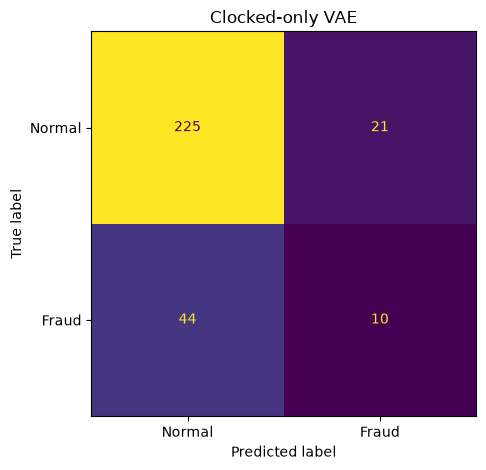

In [14]:
ConfusionMatrixDisplay(
    confusion_matrix(
        y_clocked_test,
        baseline_result["Prediction"],
    ),
    display_labels=[
        "Normal",
        "Fraud",
    ],
).plot(
    colorbar=False,
)

plt.title(
    "Clocked-only VAE"
)

plt.tight_layout()
plt.show()


12. UCI-pretrained confusion matrix

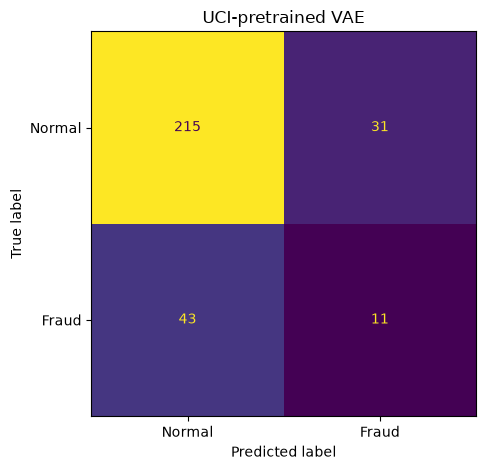

In [15]:
ConfusionMatrixDisplay(
    confusion_matrix(
        y_clocked_test,
        pretrained_result["Prediction"],
    ),
    display_labels=[
        "Normal",
        "Fraud",
    ],
).plot(
    colorbar=False,
)

plt.title(
    "UCI-pretrained VAE"
)

plt.tight_layout()
plt.show()
